# Predicting gene expression from chromatin

We predict each gene's within-cell-line expression rank from chromatin and
reference-sequence information, scored by Spearman's $\rho$. This notebook runs our complete
local cross-validation end to end: feature construction, a sweep over all model recipes,
selection of the best model of each type, and ensembles of those.

## Two feature families

* **Assay features**: summaries of the seven supplied chromatin tracks (BigWig signal and
  called BED peaks) in windows around each gene's TSS. This is the `assays_only` (or `legacy`) feature set
  (1565 columns for CatBoost), built by `prepare.py`.
* **Reference features**: GC/CpG composition and CpG-island annotation of the [hg38 UCSC reference sequence](https://hgdownload.soe.ucsc.edu/goldenPath/hg38)
  around the TSS. These are cell-line independent (so should be identical for X1, X2, X3) and are built by
  `prepare_reference.py`. Adding them to the assay features gives the `assays-ref` set (1586 columns for CatBoost).

## Models and post-hoc ordering

Three regressors -- **ridge**, **CNN**, **CatBoost** -- are each fit on **all** genes or on
**active** genes only (= those with measured `gex > 0`), using **assays_only** or **assays-ref** features.
Every regressor's ranking is then finished by one of five **post-hoc orderings** of the
predictions:

* `raw`: the regressor's scores unchanged;
* `tie`: tie the lowest scores to zero (threshold chosen on validation);
* `cal`: zero-calibration $\rightarrow$ zero scores below $\alpha\cdot$ `zero_fraction`;
* `gate`: a CatBoost activity classifier gates silent genes to zero, active genes are ranked;
* `soft`: the classifier $\times$ regressor product.

Every parameter is chosen on the **source-cell validation rows only**; target-cell labels
never inform any choice.

The `gate` and `soft` setups are inspired by [**Dong et al. (2012)**](https://doi.org/10.1186/gb-2012-13-9-r53). These are used in the 'hurdle' models that combine the output of the activity classifier and one of the three regressors.

## Evaluation

Folds are chromosome-separated (`D1 = {chr3, chr11}`, `D2 = {chr17, chr21, chr22}`); three
chromosomes are reserved and never fit. Three protocols are scored: `x1_to_x2` and `x2_to_x1`
(cross-cell transfer) and `joint` (fit and evaluate on both cells). We select models by
**mean transfer Spearman** by default (configurable below by `SELECTION_METRIC`); `joint` is reported, but not selected on.

## The Kaggle submission

The models we submitted to Kaggle are:
- CNN on `assays_only` features, all genes, with zero-calibration -- **`cnn_all[assays_only]|cal`** -- joint-trained on X1 + X2. Kaggle Score: **0.838**
- ...

The recipes submitted to Kaggle are flagged, in the sweep below.

## Setup & configuration

- If training on a GPU, for reproducibility, `CUBLAS_WORKSPACE_CONFIG` should be set before CUDA initialises so it is set before `torch`
is imported.
- The repository root is placed on `sys.path` so its modules import top-level.

In [1]:
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve the repository root by walking up from the working directory (portable across machines)
# and expose its modules for top-level import.
REPO = Path.cwd().resolve()
while not (REPO / "common.py").exists() and REPO != REPO.parent:
    REPO = REPO.parent
assert (REPO / "common.py").exists(), "Run this notebook from inside the repository."
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# CUBLAS_WORKSPACE_CONFIG must be set before torch initialises CUDA (for deterministic GPU runs),
# so torch and the repo modules (which import torch) follow it.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import torch  # noqa: E402
import common  # noqa: E402
import prepare as prepare_mod  # noqa: E402
import prepare_reference  # noqa: E402
from sweep.features import VERSIONS, tabular_features, active_mask, load_seq  # noqa: E402
from sweep.scoring import score_families, POSTHOCS  # noqa: E402
from sweep.run import run_sweep, reg_key  # noqa: E402
from sweep.models import cnn_fold  # noqa: E402

# --- configuration -------------------------------------------------------------------
DATA_DIR = REPO / "data"                      # raw assay tracks (gitignored)
INPUTS_DIR = REPO / "inputs"                  # prepared features from assays (gitignored, cached here)
REFERENCE_DIR = REPO / "data" / "reference"   # hg38 + CpG islands (prepare_reference, gitignored)
OUT_DIR = REPO / "train_interactive" / "outputs"
SWEEP_DIR = OUT_DIR / "sweep"                 # model/prediction/score cache for the recipe sweep

# Metric used to pick the "best" models everywhere below (winners, best post-hoc, table sort).
SELECTION_METRIC = "transfer_mean"            # other options: {"transfer_mean", "transfer_worst", "joint"}

# Leave False to simply load a prior run's scores (and, if present, its cached predictions)
# Set True once to train every recipe and SAVE its model, local-test predictions
# and scores under SWEEP_DIR, retraining a recipe only if its artifact is absent.
TRAIN_SAVE_MODELS = False

FORCE_PREPARE = False        # rebuild inputs/ (chromatin AND sequence) even if present
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # CPU also works, just slower

PROTOCOLS = ("x1_to_x2", "x2_to_x1", "joint")
FOLDS_USED = ("D1", "D2")
INSPECT_PROTOCOL = "joint"   # single (protocol, fold) used for the illustrative views
INSPECT_FOLD = "D1"
PICK_GENE = None             # a gene_name to inspect, or None to auto-pick a "clear" example
# -------------------------------------------------------------------------------------

# Feature-version names (VERSIONS) and the five post-hoc orderings (POSTHOCS) come from sweep.*;
# the label below only prettifies the regressor key for display.
ARCH_LABEL = {"ridge": "ridge", "cnn": "CNN", "catboost": "CatBoost"}
METRIC_COL = {"transfer_mean": "transfer_mean",
              "transfer_worst": "transfer_worst",
              "joint": "joint_mean"}[SELECTION_METRIC]

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Repo:   ", REPO)
print("Torch:  ", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:    ", torch.cuda.get_device_name(0))
else:
    print("No CUDA device found; training on CPU.")

Repo:    /home/szupernikusz/Projects/ZMSc_Semester_I/ML4Genomics/ml4g-project1
Torch:   2.11.0+cu128 | CUDA available: True
GPU:     NVIDIA GeForce RTX 5060 Laptop GPU


### Determinism

We seed `random`, `numpy` and `torch` with 42 per fold, enable deterministic algorithms and
disable cuDNN autotuning, so GPU training is reproducible.
This is empirically verified at the end of the notebook.

In [2]:
def apply_determinism(strict: bool = True) -> None:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not strict)
    except TypeError:
        torch.use_deterministic_algorithms(True)
    torch.set_num_threads(2)


apply_determinism()
print("Deterministic algorithms:", torch.are_deterministic_algorithms_enabled(),
      "| CUBLAS_WORKSPACE_CONFIG =", os.environ.get("CUBLAS_WORKSPACE_CONFIG"))

Deterministic algorithms: True | CUBLAS_WORKSPACE_CONFIG = :4096:8


## Stage 0 — the raw data

Per cell line we have: per-gene information (chromosome, gene-body and TSS
coordinates, strand), the CAGE expression labels, and for each of seven assays a genome-wide BigWig signal and a called-peak BED file. The notebook locates files with `prepare.py`'s own helpers.

In [3]:
from prepare import MARKS, discover, unique, track_file  # noqa: E402
import pyBigWig  # noqa: E402

raw_files = discover(DATA_DIR, INPUTS_DIR)
info_x1 = pd.read_csv(unique(raw_files, "X1_train_info.tsv"), sep="\t")
y_x1 = pd.read_csv(unique(raw_files, "X1_train_y.tsv"), sep="\t")
raw_x1 = info_x1.merge(y_x1, on="gene_name", validate="one_to_one")
print(f"X1 train: {len(raw_x1)} genes, {len(MARKS)} assays ({', '.join(MARKS)})")
raw_x1.head()

X1 train: 14310 genes, 7 assays (DNase, H3K4me3, H3K4me1, H3K27ac, H3K36me3, H3K27me3, H3K9me3)


,gene_name,chr,gene_start,gene_end,TSS_start,TSS_end,strand,gex
0,SLC20A1,chr2,112645939,112663825,112658362,112658412,+,0.000000
1,C11orf58,chr11,16613132,16758340,16738643,16738693,+,2239.103328
2,ZSCAN9,chr6,28224886,28233487,28225263,28225313,+,19.798064
3,CD19,chr16,28931965,28939342,28931956,28932006,+,411.530623
4,TMEM123,chr11,102396332,102470384,102452789,102452839,-,34.214129


### Expression labels are strongly zero-inflated

Many genes are silent. Consequently, we predict a within-cell rank (as the metric is Spearman's $\rho$) and map the lowest predictions to exactly zero.

This zero-inflation is also what the hurdle [(Dong et al. (2012))](https://doi.org/10.1186/gb-2012-13-9-r53) targets explicitly: an activity classifier separates silent from active genes before ranking.

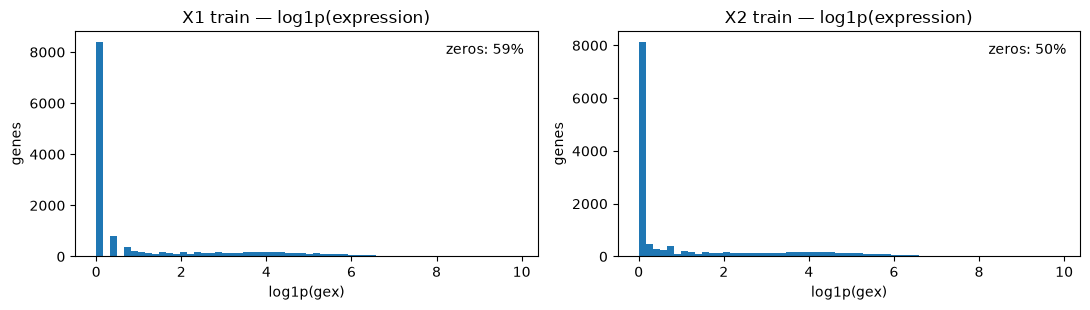

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
y_x2 = pd.read_csv(unique(raw_files, "X2_train_y.tsv"), sep="\t")
for a, (name, y) in zip(ax, [("X1", raw_x1.gex), ("X2", y_x2.gex)]):
    a.hist(np.log1p(y), bins=60)
    a.set_title(f"{name} train — log1p(expression)")
    a.set_xlabel("log1p(gex)")
    a.set_ylabel("genes")
    a.text(0.97, 0.9, f"zeros: {(y == 0).mean():.0%}", ha="right", transform=a.transAxes)
fig.tight_layout()
plt.show()

### Raw BigWig signal around one gene's TSS

For a chosen gene we read the raw ±5 kb BigWig signal for every assay. This is the window `prepare.py` bins into the CNN's spatial `profile`.

- DNase/H3K4me3/H3K27ac should mark expression
- H3K27me3/H3K9me3 should mark repression.

Inspecting EIF4A1 on chr17 (strand +), TSS~7,572,843, expression=3278.021


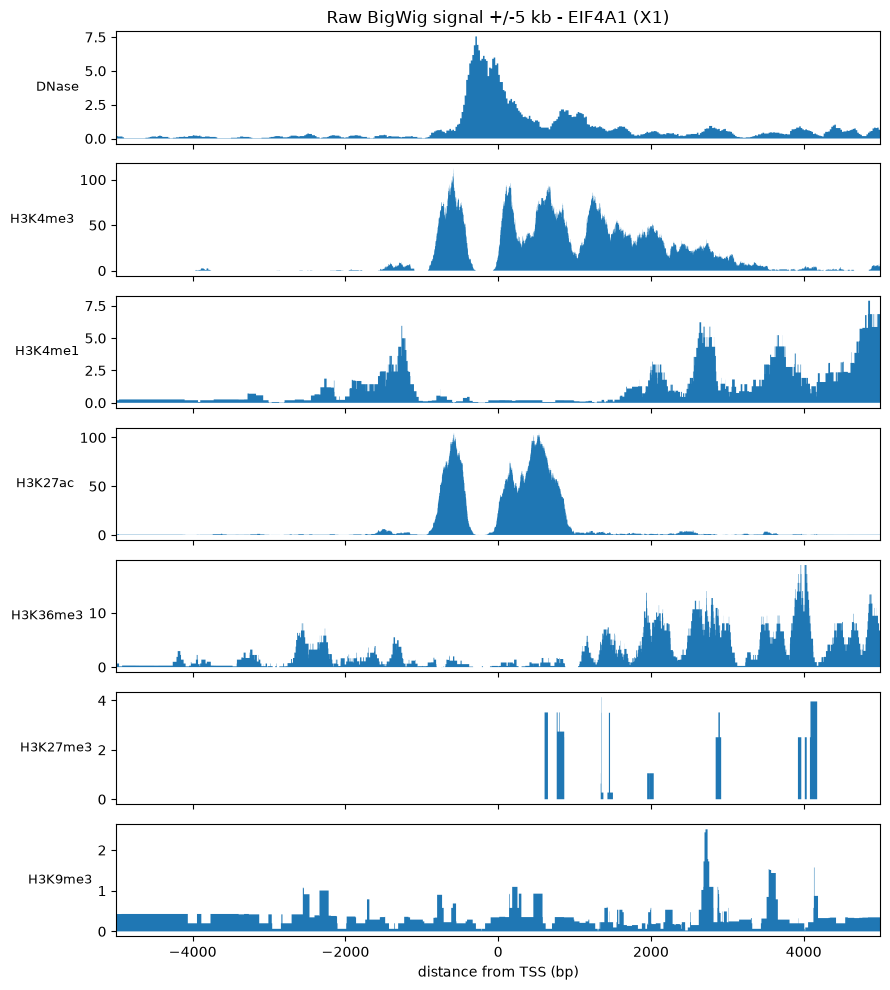

In [5]:
PICK_GENE = "EIF4A1" # or e.g., "SLC20A1"

def _pick_gene(info, labels, name=None):
    merged = info.merge(labels, on="gene_name", validate="one_to_one")
    if name is not None:
        return merged.loc[merged.gene_name == name].iloc[0]
    pool = merged[merged.chr.isin(["chr19", "chr17", "chr22"])]
    return (pool if len(pool) else merged).sort_values("gex", ascending=False).iloc[0]


gene = _pick_gene(info_x1, y_x1, PICK_GENE)
tss = (int(gene.TSS_start) + int(gene.TSS_end)) // 2
print(f"Inspecting {gene.gene_name} on {gene.chr} (strand {gene.strand}), "
      f"TSS~{tss:,}, expression={gene.gex:.3f}")

fig, axes = plt.subplots(len(MARKS), 1, figsize=(9, 10), sharex=True)
xs = np.arange(tss - 5000, tss + 5000)
for ax, mark in zip(axes, MARKS):
    with pyBigWig.open(str(track_file(raw_files, mark, "X1", "bw"))) as bw:
        vals = np.asarray(bw.values(gene.chr, tss - 5000, tss + 5000), dtype=np.float32)
    ax.fill_between(xs - tss, np.nan_to_num(vals), step="mid", linewidth=0)
    ax.set_ylabel(mark, rotation=0, ha="right", va="center", fontsize=9)
    ax.margins(x=0)
axes[-1].set_xlabel("distance from TSS (bp)")
axes[0].set_title(f"Raw BigWig signal +/-5 kb - {gene.gene_name} (X1)")
fig.tight_layout()
plt.show()

## Stage 1 -- assay features (`prepare.py`)

`prepare.prepare` reads the seven assay tracks and summarises each one around every gene's TSS
(TSS-centred, strand-oriented, strand-mirrored windows). Uncovered
positions stay `NaN`, and coverage is stored separately so "missing" never reads as a measured
zero. With N = 32,568 gene-rows and 7 assays, it writes:

| Array | Shape | Origin and meaning |
|---|---|---|
| `metadata.csv` | (N, cols) | gene table: cell_line, gene_name, chr, gex, gene/TSS coords, strand |
| `features.npz: bw56` | (N, 7x8) | mean BigWig signal in 8 regions per assay (5 promoter-derived + 3 gene-body-derived) |
| `features.npz: coverage56` | (N, 7x8) | covered-base fraction of those same 8 regions |
| `features.npz: bed7` | (N, 7) | largest overlapping BED peak `signalValue` per assay |
| `features.npz: profile` | (N, 7x100) | mean BigWig signal in 100 bins of 100 bp over +/-5 kb of the TSS |
| `features.npz: profile_coverage` | (N, 7x100) | covered-base fraction of each of those 100 bins |
| `tree_features.npy` | (N, 1565) | the tabular (CatBoost/ridge) matrix, built from the arrays above |

`bw56`, `coverage56` and `bed7` feed both the tabular models and the CNN's tabular branch;
`profile` and `profile_coverage` (7 assays x 100 positions) feed the CNN's spatial branch.

The 1565 tabular columns concatenate:
- the 56 + 56 + 7 coarse features above
- distal +/-20/100 kb
- context rings (56)
- per-assay spatial bins (means and coverage) at +/-5 kb (700), +/-20 kb (280)
and +/-100 kb (280)
- relative/geometry features (local signal shape 70, relative coarse
means 56, annotation geometry 4).

This reads ~16 GB of BigWig (~20-40 min) and is cached: it runs only if `inputs/` is missing or
`FORCE_PREPARE=True`; otherwise the cells below load the cached arrays.

In [6]:
if FORCE_PREPARE or not (INPUTS_DIR / "features.npz").exists():
    print("Running prepare.prepare(...) which reads the raw tracks, ~20–40 min.")
    t0 = time.time()
    prepare_mod.prepare(DATA_DIR, INPUTS_DIR)
    print(f"prepare finished in {(time.time() - t0) / 60:.1f} min")
else:
    print("inputs/features.npz present -- loading cached arrays (set FORCE_PREPARE=True to rebuild).")

m, data = common.load_inputs(INPUTS_DIR)
tree_x = np.load(INPUTS_DIR / "tree_features.npy")
assert tree_x.shape == (len(m), 1565)
print(f"\nLoaded {len(m):,} gene rows "
      f"({(m.cell_line == 'X1').sum():,} X1 / {(m.cell_line == 'X2').sum():,} X2)")
for k, v in data.items():
    print(f"  features.npz[{k:16}] {str(v.shape):14} {v.dtype}")
print(f"  tree_features.npy (assays_only) {tree_x.shape}")

inputs/features.npz present -- loading cached arrays (set FORCE_PREPARE=True to rebuild).

Loaded 32,568 gene rows (16,284 X1 / 16,284 X2)
  features.npz[bw56            ] (32568, 56)    float32
  features.npz[coverage56      ] (32568, 56)    float32
  features.npz[bed7            ] (32568, 7)     float32
  features.npz[profile         ] (32568, 7, 100) float32
  features.npz[profile_coverage] (32568, 7, 100) float32
  tree_features.npy (assays_only) (32568, 1565)


## Stage 2 -- reference features (`prepare_reference.py`)

These describe the hg38 sequence around each TSS and are cell-line independent. There are 21,
in two families:

* **GC/CpG composition** over three strand-oriented windows (`core` [−200,+100),
  `proximal` [−500,+500), `broad` [−1500,+1500)): `gc_frac`, `cpg_count`, `cpg_density`,
  `cpg_oe` (observed/expected CpG), `unambig_frac`.
* **CpG-island annotation** from the UCSC `cpgIslandExt` table: `tss_in_island`, `island_dist`,
  `island_on_chr`, and `island_frac_{core,proximal,broad}`.

CpG-island, high-GC promoters are a hallmark of broadly expressed genes, so these add signal
the chromatin tracks do not encode directly. Together with the assay matrix they form the
`assays-ref` feature set. Regenerating them downloads ~0.8 GB (hg38 + islands) into
`data/reference/`; cached by default.

During development, we additionally tried downloading TF information and scoring DNA sequence segments based on TF_strength $\times$ DNase_signal. This, however, turned out to be disadvantageous for our models' performance on our local test set. Consequently, we omit these from this demonstration and from our uploaded solution.

In [7]:
if FORCE_PREPARE or not (INPUTS_DIR / "seq_features.npy").exists():
    print("Building reference features (downloads ~0.8 GB on first run)...")
    t0 = time.time()
    prepare_reference.prepare_reference(INPUTS_DIR, REFERENCE_DIR)
    print(f"prepare_reference finished in {(time.time() - t0) / 60:.1f} min")
else:
    print("inputs/seq_features.npy present. Loading cached data (set FORCE_PREPARE=True to rebuild).")

seq, seq_schema = load_seq(INPUTS_DIR)
assert seq.shape == (len(m), len(seq_schema))
col = {c["name"]: seq[:, i] for i, c in enumerate(seq_schema)}
print(f"\nseq_features.npy: {seq.shape} | finite fraction: {np.isfinite(seq).mean():.3f}")
for v in VERSIONS:
    x = tabular_features(tree_x, INPUTS_DIR, v)
    print(f"  {v:11} -> {x.shape[1]} columns "
          f"(= 1565 assay + {x.shape[1] - 1565} reference)")

inputs/seq_features.npy present. Loading cached data (set FORCE_PREPARE=True to rebuild).

seq_features.npy: (32568, 21) | finite fraction: 1.000
  assays_only -> 1565 columns (= 1565 assay + 0 reference)
  assays-ref  -> 1586 columns (= 1565 assay + 21 reference)


### What the reference features look like

Distributions of a few reference features, and expression split by whether the TSS sits in a CpG island.
This should be a clean, cell-line-independent correlate of expression.

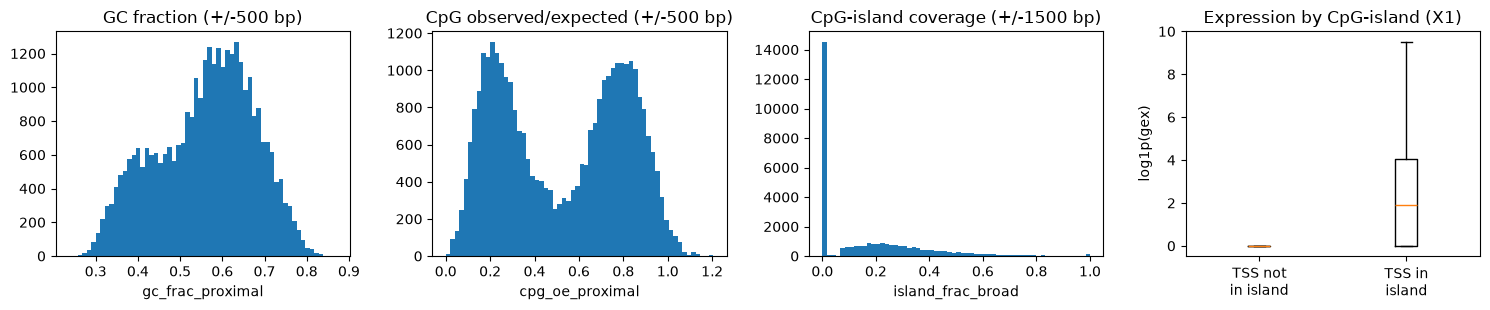

TSS in CpG island (X1): 44.0% | median log1p(gex) in-island=1.93 vs out=0.00


In [8]:
x1 = (m.cell_line == "X1").to_numpy()
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
ax[0].hist(col["gc_frac_proximal"][np.isfinite(col["gc_frac_proximal"])], bins=60)
ax[0].set_title("GC fraction (+/-500 bp)")
ax[0].set_xlabel("gc_frac_proximal")
ax[1].hist(col["cpg_oe_proximal"][np.isfinite(col["cpg_oe_proximal"])], bins=60)
ax[1].set_title("CpG observed/expected (+/-500 bp)")
ax[1].set_xlabel("cpg_oe_proximal")
ax[2].hist(col["island_frac_broad"], bins=60)
ax[2].set_title("CpG-island coverage (+/-1500 bp)")
ax[2].set_xlabel("island_frac_broad")
in_island = col["tss_in_island"][x1] > 0.5
gex_x1 = m.loc[x1, "gex"].to_numpy()
ax[3].boxplot([np.log1p(gex_x1[~in_island]), np.log1p(gex_x1[in_island])], showfliers=False)
ax[3].set_xticks([1, 2], ["TSS not\nin island", "TSS in\nisland"])
ax[3].set_title("Expression by CpG-island (X1)")
ax[3].set_ylabel("log1p(gex)")
fig.tight_layout()
plt.show()
print(f"TSS in CpG island (X1): {in_island.mean():.1%} | median log1p(gex) "
      f"in-island={np.median(np.log1p(gex_x1[in_island])):.2f} "
      f"vs out={np.median(np.log1p(gex_x1[~in_island])):.2f}")

## Stage 3 — the CNN's view, splits and rank targets

After `prepare`, a gene's promoter is a strand-oriented 7×100 `profile` plus its coverage;
`cnn/model.py` signed-log-transforms and standardises these on training rows only. `common.masks`
returns three disjoint masks per (protocol, fold): **train** (source cell, non-reserved,
non-fold chromosomes), **validation** (source cell, fold chromosomes; used only to pick
post-hoc parameters) and **evaluate** (target cell, fold chromosomes; the scored rows).
`common.targets` builds the within-cell empirical rank target on training rows. For the
active-gene recipes, `active_mask` (from `sweep.features`) restricts fitting to measured-active genes.

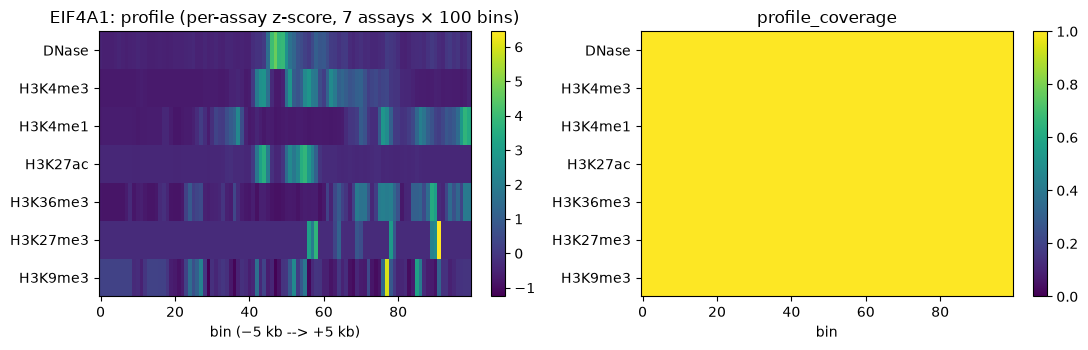

In [9]:
# Choose gene to visualize
PICK_GENE = "EIF4A1"
gene = _pick_gene(info_x1, y_x1, PICK_GENE)

gi = int(np.flatnonzero((m.cell_line == "X1") & (m.gene_name == gene.gene_name))[0])
prof, cov = data["profile"][gi], data["profile_coverage"][gi]
# Normalize each assay to its own z-score across the 100 bins, so assays with weaker overall
# signal stay visible beside stronger ones (otherwise high-amplitude assays dominate the scale).
prof_disp = np.nan_to_num(prof)
prof_sd = prof_disp.std(axis=1, keepdims=True)
prof_z = (prof_disp - prof_disp.mean(axis=1, keepdims=True)) / np.where(prof_sd > 0, prof_sd, 1.0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
im0 = ax[0].imshow(prof_z, aspect="auto", interpolation="nearest")
ax[0].set_title(f"{gene.gene_name}: profile (per-assay z-score, 7 assays × 100 bins)")
ax[0].set_yticks(range(7), MARKS)
ax[0].set_xlabel("bin (−5 kb --> +5 kb)")
fig.colorbar(im0, ax=ax[0], fraction=0.046)
im1 = ax[1].imshow(cov, aspect="auto", interpolation="nearest", vmin=0, vmax=1)
ax[1].set_title("profile_coverage")
ax[1].set_yticks(range(7), MARKS)
ax[1].set_xlabel("bin")
fig.colorbar(im1, ax=ax[1], fraction=0.046)
fig.tight_layout()
plt.show()

protocol=joint fold=D1
  train     :  25470 rows  chrs=['chr10', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9'] cells=['X1', 'X2']
  validation:   4590 rows  chrs=['chr11', 'chr3'] cells=['X1', 'X2']
  evaluate  :   4590 rows  chrs=['chr11', 'chr3'] cells=['X1', 'X2']
  active-only fit rows (gex>0):  11848 (46.5% of train)


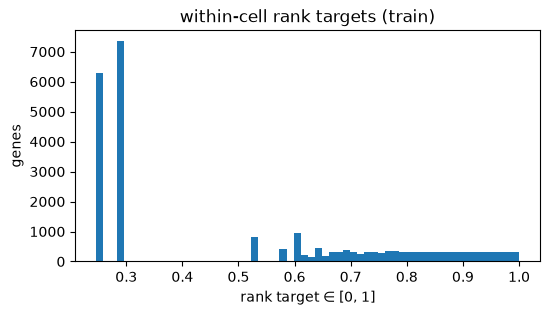

In [10]:
_tr, _va, _ev = common.masks(m, INSPECT_PROTOCOL, INSPECT_FOLD)
print(f"protocol={INSPECT_PROTOCOL} fold={INSPECT_FOLD}")
for name, msk in [("train", _tr), ("validation", _va), ("evaluate", _ev)]:
    print(f"  {name:10}: {msk.sum():6d} rows  chrs={sorted(set(m.loc[msk, 'chr']))} "
          f"cells={sorted(set(m.loc[msk, 'cell_line']))}")
_active = active_mask(m, _tr)
print(f"  active-only fit rows (gex>0): {_active.sum():6d} ({_active.sum() / _tr.sum():.1%} of train)")

_t = common.targets(m, _tr)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(_t, bins=60)
ax.set_title("within-cell rank targets (train)")
ax.set_xlabel("rank target ∈ [0, 1]")
ax.set_ylabel("genes")
plt.show()

## Stage 4 -- train all recipes and select the best

We sweep every recipe: three regressors $\times$ {all, active} genes $\times$ {assays_only, assays-ref}
features, each finished by all five post-hoc orderings $\rightarrow$ **60 configurations**. Each regressor
fold is trained once; the five orderings are cheap transforms of the regressor's raw output, with
parameters chosen on the source-cell validation rows.

In [11]:
# Train-and-save, load-scores, or train-in-memory, per TRAIN_SAVE_MODELS and the cache state.
# The sweep itself is defined in sweep/run.py; here we only drive it and keep its results.
if TRAIN_SAVE_MODELS:
    print("TRAIN_SAVE_MODELS=True — training/caching every recipe (retrains only what is missing).")
    sweep = run_sweep(INPUTS_DIR, SWEEP_DIR, device=DEVICE, save=True)
elif (SWEEP_DIR / "summary.csv").exists():
    print("Loading cached scores from", SWEEP_DIR)
    sweep = dict(experiments=pd.read_csv(SWEEP_DIR / "experiments.csv"),
                 summary=pd.read_csv(SWEEP_DIR / "summary.csv"),
                 diagnostics=pd.read_csv(SWEEP_DIR / "classifier_metrics.csv"),
                 registry=None)
else:
    print("No cache present — running the sweep in memory (scores + predictions, not persisted).")
    sweep = run_sweep(INPUTS_DIR, SWEEP_DIR, device=DEVICE, save=False)

summary = sweep["summary"]
print(f"Scored {len(summary)} recipe families.")

Loading cached scores from /home/szupernikusz/Projects/ZMSc_Semester_I/ML4Genomics/ml4g-project1/train_interactive/outputs/sweep
Scored 60 recipe families.


In [12]:
def parse_family(family):
    """'cnn_all[assays_only]|cal' -> ('cnn', 'all', 'assays_only', 'cal')."""
    regressor, rest = family.split("_", 1)
    mode, rest = rest.split("[", 1)
    version, recipe = rest.split("]|", 1)
    return regressor, mode, version, recipe


# Tidy, relabelled view of the sweep scores (the three regressors; the classifier is diagnostic).
_rows_tidy = []
for _, r in summary.iterrows():
    reg, mode, version, recipe = parse_family(r.family)
    if reg not in ARCH_LABEL:
        continue
    _rows_tidy.append(dict(_family=r.family, _reg=reg,
                           architecture=ARCH_LABEL[reg], genes=mode,
                           features=version, posthoc_ordering=recipe,
                           transfer_mean=r.transfer_mean, transfer_worst=r.transfer_worst,
                           joint_mean=r.joint_mean))
tidy = pd.DataFrame(_rows_tidy)
tidy["submission"] = tidy._family.eq("cnn_all[assays_only]|cal")

### All 60 recipes, ranked

Each row is one configuration. `submission=True` marks the recipes we submitted to Kaggle. 

Scores are per-cell Spearman, averaged over the transfer
directions and folds (`transfer_mean`), their minimum (`transfer_worst`), and the joint
protocol (`joint_mean`).
The table is sorted by the selection metric (`SELECTION_METRIC`).

In [13]:
pd.set_option("display.max_rows", None, "display.width", 180)
headline = (tidy.sort_values(METRIC_COL, ascending=False)
            [["architecture", "genes", "features", "posthoc_ordering",
              "transfer_mean", "transfer_worst", "joint_mean", "submission"]]
            .round(4).reset_index(drop=True))
headline

,architecture,genes,features,posthoc_ordering,transfer_mean,transfer_worst,joint_mean,submission
0,CNN,all,assays_only,gate,0.8086,0.7854,0.8480,False
1,CNN,all,assays-ref,gate,0.8172,0.7988,0.8465,False
2,CNN,active,assays_only,gate,0.8090,0.7905,0.8462,False
3,CNN,all,assays-ref,cal,0.8244,0.8103,0.8456,False
4,CNN,all,assays-ref,tie,0.8251,0.8051,0.8453,False
5,CNN,active,assays-ref,gate,0.8151,0.7899,0.8445,False
6,CNN,all,assays_only,tie,0.8224,0.8034,0.8433,False
7,CatBoost,all,assays-ref,cal,0.8156,0.7909,0.8428,False
8,CNN,all,assays_only,cal,0.8219,0.7997,0.8426,True
9,CatBoost,all,assays_only,tie,0.8115,0.7806,0.8416,False


### The effect of post-hoc ordering

To read the orderings' effect cleanly we first drop them (the `raw` regressors, one row per
recipe type), then plot how each ordering moves the selection metric, then keep only the best
ordering per recipe type.

In [14]:
raw_table = (tidy[tidy.posthoc_ordering == "raw"].sort_values(METRIC_COL, ascending=False)
             [["architecture", "genes", "features",
               "transfer_mean", "transfer_worst", "joint_mean"]]
             .round(4).reset_index(drop=True))
raw_table

,architecture,genes,features,transfer_mean,transfer_worst,joint_mean
0,CNN,all,assays-ref,0.7953,0.7801,0.8168
1,CNN,all,assays_only,0.7907,0.7731,0.8147
2,CatBoost,all,assays-ref,0.7850,0.7679,0.8132
3,CatBoost,all,assays_only,0.7836,0.7681,0.8114
4,ridge,all,assays-ref,0.7800,0.7701,0.7917
5,ridge,all,assays_only,0.7771,0.7683,0.7895
6,CNN,active,assays_only,0.7525,0.7323,0.7566
7,CatBoost,active,assays-ref,0.7324,0.6928,0.7566
8,CatBoost,active,assays_only,0.7375,0.7022,0.7553
9,CNN,active,assays-ref,0.7558,0.7340,0.7538


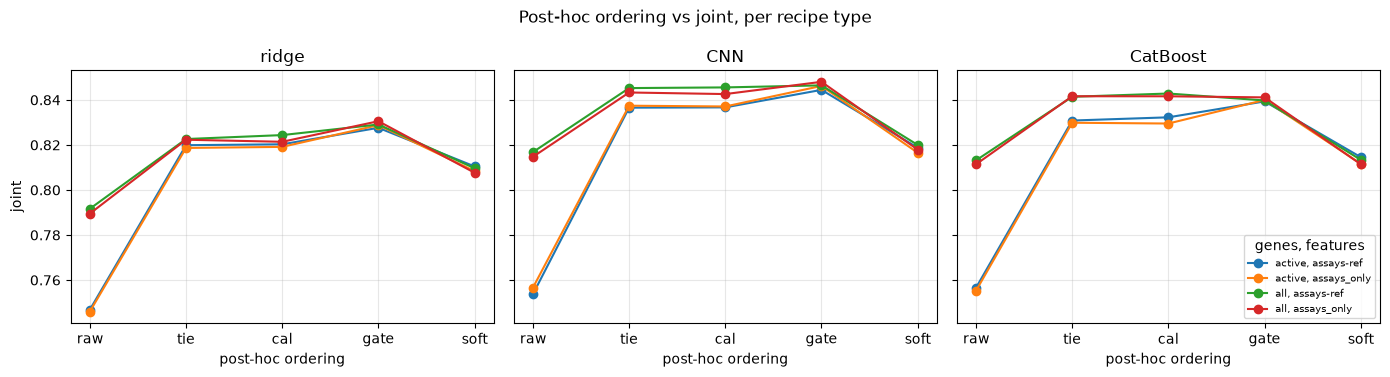

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, arch in zip(axes, ["ridge", "CNN", "CatBoost"]):
    sub = tidy[tidy.architecture == arch]
    for (g, f), grp in sub.groupby(["genes", "features"]):
        grp = grp.set_index("posthoc_ordering").reindex(POSTHOCS)
        ax.plot(POSTHOCS, grp[METRIC_COL], marker="o", label=f"{g}, {f}")
    ax.set_title(arch)
    ax.set_xlabel("post-hoc ordering")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(SELECTION_METRIC)
axes[-1].legend(fontsize=7, title="genes, features")
fig.suptitle(f"Post-hoc ordering vs {SELECTION_METRIC}, per recipe type")
fig.tight_layout()
plt.show()

#### Interpretation & Conclusions:
- Post-hoc ordering substantially improves all model types
- Best scores when training on all genes and using a threshold (`tie` or `cal`) to zero out low predictions
- CNN performs best in essentially all possible setups

Note that for the regressors trained only on the active genes (marked with the prefix `acctive_`), the `raw`, `tie`, and `cal` setups trivially perform weakly, since active-only regressors have never seen zero-expression genes. These models, therefore, require the `gate` or `soft` type post-hoc ordering for proper scoring of the models.

### Best individual model scores

In [16]:
# Best ordering per recipe type (architecture x genes x features), by the selection metric.
best_posthoc = (tidy.loc[tidy.groupby(["architecture", "genes", "features"])[METRIC_COL].idxmax()]
                .sort_values(METRIC_COL, ascending=False)
                [["architecture", "genes", "features", "posthoc_ordering",
                  "transfer_mean", "transfer_worst", "joint_mean"]]
                .round(4).reset_index(drop=True))
best_posthoc

,architecture,genes,features,posthoc_ordering,transfer_mean,transfer_worst,joint_mean
0,CNN,all,assays_only,gate,0.8086,0.7854,0.8480
1,CNN,all,assays-ref,gate,0.8172,0.7988,0.8465
2,CNN,active,assays_only,gate,0.8090,0.7905,0.8462
3,CNN,active,assays-ref,gate,0.8151,0.7899,0.8445
4,CatBoost,all,assays-ref,cal,0.8156,0.7909,0.8428
5,CatBoost,all,assays_only,tie,0.8115,0.7806,0.8416
6,CatBoost,active,assays_only,gate,0.8034,0.7824,0.8400
7,CatBoost,active,assays-ref,gate,0.8106,0.7874,0.8393
8,ridge,all,assays_only,gate,0.8008,0.7846,0.8305
9,ridge,all,assays-ref,gate,0.8078,0.7945,0.8291


### Activity-classifier diagnostics (reported, not selected on)

This CatBoost classifier drives the `gate` and `soft` orderings (important for `active_only` models), scored on the target cell.

In [17]:
sweep["diagnostics"].round(4)

,version,protocol,fold,cell_line,pos_fraction,auroc,avg_precision,log_loss,brier
0,assays_only,x1_to_x2,D1,X2,0.4954,0.9231,0.9232,0.3692,0.1145
1,assays-ref,x1_to_x2,D1,X2,0.4954,0.9282,0.9283,0.3552,0.1112
2,assays_only,x1_to_x2,D2,X2,0.4668,0.8982,0.8946,0.4047,0.1278
3,assays-ref,x1_to_x2,D2,X2,0.4668,0.9018,0.8951,0.3966,0.1247
4,assays_only,x2_to_x1,D1,X1,0.4087,0.9391,0.9254,0.3235,0.0954
5,assays-ref,x2_to_x1,D1,X1,0.4087,0.9384,0.9226,0.3228,0.0955
6,assays_only,x2_to_x1,D2,X1,0.4037,0.9322,0.9162,0.3321,0.1006
7,assays-ref,x2_to_x1,D2,X1,0.4037,0.9321,0.9126,0.3298,0.0992
8,assays_only,joint,D1,X1,0.4087,0.9486,0.9359,0.2804,0.0856
9,assays_only,joint,D1,X2,0.4954,0.9421,0.9412,0.3084,0.0964


## Stage 5 — the best model of each type

We select the best ridge, CNN and CatBoost recipe by the selection metric (`SELECTION_METRIC`).
These three models are the members of the ensembles in Stage 6.

In [18]:
winners = {arch: tidy[tidy._reg == arch].sort_values(METRIC_COL, ascending=False).iloc[0]
           for arch in ("cnn", "catboost", "ridge")}
print("Best model of each type (by", SELECTION_METRIC + "):")
for arch, w in winners.items():
    print(f"  {ARCH_LABEL[arch]:9} {w.genes:6} {w.features:11} {w.posthoc_ordering:4}  "
          f"transfer_mean={w.transfer_mean:.4f} joint_mean={w.joint_mean:.4f}")


def config_frame(family, protocol, fold):
    """Blend-ready evaluate frame (keys, gex, scored prediction, raw prediction) for one recipe.

    Sourced from the in-memory sweep, or from the saved prediction cache; never refit. Returns
    None if neither is available (i.e. no prior TRAIN_SAVE_MODELS run)."""
    kind, mode, version, recipe = parse_family(family)
    _, _, evaluate = common.masks(m, protocol, fold)
    base = m.loc[evaluate, ["cell_line", "gene_name", "chr", "gex"]].copy()
    base.insert(0, "fold", fold)
    reg_mem = sweep["registry"]
    if reg_mem is not None and (family, protocol, fold) in reg_mem["scored"]:
        scored = reg_mem["scored"][(family, protocol, fold)]
        raw = reg_mem["raw"][(kind, mode, version, protocol, fold)]
    else:
        ppath = SWEEP_DIR / "preds" / f"{reg_key(kind, mode, version, protocol, fold)}.npz"
        cpath = SWEEP_DIR / "clf_preds" / f"{version}_{protocol}_{fold}.npz"
        if not ppath.exists():
            return None
        z = np.load(ppath)
        train, validation, _ = common.masks(m, protocol, fold)
        reg = dict(train=train, validation=validation, evaluate=evaluate,
                   raw_val=z["raw_val"], raw=z["raw"])
        clf_pair = None
        if cpath.exists():
            cz = np.load(cpath)
            clf_pair = dict(p_val=cz["p_val"], p_eval=cz["p_eval"])
        scored, _ = score_families(m, reg, clf_pair)[recipe]
        raw = np.asarray(reg["raw"], float)
    base["prediction"] = np.asarray(scored, float)
    base["raw_prediction"] = np.asarray(raw, float)
    return base.reset_index(drop=True)

Best model of each type (by joint):
  CNN       all    assays_only gate  transfer_mean=0.8086 joint_mean=0.8480
  CatBoost  all    assays-ref  cal   transfer_mean=0.8156 joint_mean=0.8428
  ridge     all    assays_only gate  transfer_mean=0.8008 joint_mean=0.8305


## Stage 6 -- ensembles of the best models

We blend the rank predictions of the best models with `equal_rank_blend` (equal average-tie ranks within each cell and fold).
There will be four ensembles in total:
- CNN_best & CatBoost_best
- CNN_best & Ridge_best
- CatBoost_best & Ridge_best
- CNN_best & CatBoost_best & Ridge_best

Each ensemble is scored exactly like the single models, which are displayed as well for reference.

In [19]:
def equal_rank_blend(components):
    """Average-tie rank blend within each (fold, cell), summed over components."""
    from scipy.stats import rankdata
    keys = ["fold", "cell_line", "gene_name", "chr"]
    base = components[0][keys + ["gex"]].copy()
    stacked = base.copy()
    stacked["prediction"] = 0.0
    for comp in components:
        merged = base.merge(comp[keys + ["prediction"]], on=keys, validate="one_to_one")
        for _, idx in merged.groupby(["fold", "cell_line"]).groups.items():
            stacked.loc[idx, "prediction"] += np.rint(
                2 * rankdata(merged.loc[idx, "prediction"])).astype(np.int64)
    return stacked


def folder_scores(folder):
    scores = common.summarize(folder)              # also writes metrics.csv
    metrics = pd.read_csv(Path(folder) / "metrics.csv")
    transfer = metrics[metrics.protocol.isin(["x1_to_x2", "x2_to_x1"])]
    return dict(transfer_mean=float(np.mean([scores[p] for p in ("x1_to_x2", "x2_to_x1")])),
                transfer_worst=float(transfer.spearman.min()),
                joint_mean=float(scores.get("joint", np.nan)))

In [20]:
cache_ready = all(config_frame(w._family, p, fold) is not None
                  for w in winners.values() for p in PROTOCOLS for fold in FOLDS_USED)
if not cache_ready:
    print("Prediction cache absent -- ensembles are skipped (run once with TRAIN_SAVE_MODELS=True).")
else:
    members = {arch: {p: pd.concat([config_frame(w._family, p, fold) for fold in FOLDS_USED],
                                   ignore_index=True) for p in PROTOCOLS}
               for arch, w in winners.items()}
    combos = {"CNN + CatBoost": ("cnn", "catboost"),
              "CNN + ridge": ("cnn", "ridge"),
              "CatBoost + ridge": ("catboost", "ridge"),
              "CNN + CatBoost + ridge": ("cnn", "catboost", "ridge")}
    rows = []
    for arch, w in winners.items():                # single models, for reference
        rows.append(dict(model=f"best {ARCH_LABEL[arch]} "
                         f"({w.genes}/{w.features}/{w.posthoc_ordering})",
                         transfer_mean=w.transfer_mean, transfer_worst=w.transfer_worst,
                         joint_mean=w.joint_mean))
    for name, archs in combos.items():
        out = OUT_DIR / "ensembles" / name.replace(" ", "").replace("+", "_")
        out.mkdir(parents=True, exist_ok=True)
        for p in PROTOCOLS:
            equal_rank_blend([members[a][p] for a in archs]).to_csv(out / (p + ".csv"), index=False)
        rows.append(dict(model=name, **folder_scores(out)))
    comparison = pd.DataFrame(rows).round(4)
    display(comparison)

,model,transfer_mean,transfer_worst,joint_mean
0,best CNN (all/assays_only/gate),0.8086,0.7854,0.8480
1,best CatBoost (all/assays-ref/cal),0.8156,0.7909,0.8428
2,best ridge (all/assays_only/gate),0.8008,0.7846,0.8305
3,CNN + CatBoost,0.8177,0.7911,0.8492
4,CNN + ridge,0.8087,0.7881,0.8438
5,CatBoost + ridge,0.8151,0.7924,0.8404
6,CNN + CatBoost + ridge,0.8175,0.7924,0.8460


## Small determinism check (for GPU)

We train the same CNN fold twice and compare the raw predictions. A maximum difference of
exactly `0.0` confirms the GPU training is bit-reproducible, so every recipe and ensemble
above is reproducible. Note that this holds only for models trained on the same machines -- differences across models trained on different machines may still persist.

In [21]:
_a = cnn_fold(m, data, INPUTS_DIR, INSPECT_PROTOCOL, INSPECT_FOLD, DEVICE, "assays_only", False)
_b = cnn_fold(m, data, INPUTS_DIR, INSPECT_PROTOCOL, INSPECT_FOLD, DEVICE, "assays_only", False)
_maxdiff = float(np.abs(np.asarray(_a["raw"]) - np.asarray(_b["raw"])).max())
del _a, _b
if DEVICE == "cuda":
    torch.cuda.empty_cache()
print(f"max diff between two identical CNN runs: {_maxdiff:.3e}, so it is "
      f"{'DETERMINISTIC' if _maxdiff == 0 else 'NON-deterministic'}")

max diff between two identical CNN runs: 0.000e+00, so it is DETERMINISTIC


## Stage 8 -- combining the sweep models with the 14-model ensemble (greedy sweep)

Starting from the frozen 14-model ensemble (replayed from its checkpoints and recipe; its
joint-D1 score is the baseline below), we add the best assays-ref sweep models one staged rank
step at a time -- `ensemble14 -> +model.ordering.w -> ...` -- each (model, ordering, weight)
chosen with the previous additions already in place, exactly as the ensemble's own `ensemble_14`
recipe adds its members. Every trial at every round is kept as a full combined recipe, so the
table below is the ranked menu from which the two blended submissions were picked (flagged
`on_greedy_path`):

* `blend-16-cnn-catboost` = `ensemble-14 + cnn.gate.w40 + catboost.cal.w5`  -- best local (joint-D1 ~0.8567)
* `blend-15-cnn`          = `ensemble-14 + cnn.gate.w40`                    -- single-CNN addition (~0.8563)

This is a **D1-only** comparison: 9 of the 14 ensemble runners validate on a single fixed split
that equals the joint-D1 fold, so the ensemble side has no D2 and only D1 is a common held-out
fold. The sweep only blends the cached OOF (`combined/oof_ensemble/`, `combined/oof_sweep/`), so
it reruns in seconds. (`combined/cross_product.py` additionally records the one-fused-unit view.)

In [ ]:
from combined.combined_sweep import load_oof, run_combined_sweep

_ensemble14, _sweep = load_oof(REPO)
_top = run_combined_sweep(_ensemble14, _sweep)
_baseline = float(_top.loc[_top.recipe == "ensemble-14", "joint_mean"].iloc[0])
print(f"ensemble-14 joint-D1 baseline: {_baseline:.4f}   (the two submission recipes are "
      f"flagged on_greedy_path; rows below baseline flagged below_baseline)")
display(_top[["recipe", "n_add", "X1", "X2", "joint_worst", "joint_mean",
              "delta_vs_ensemble14", "on_greedy_path", "below_baseline"]].head(20))